In [ ]:
from google.colab import drive
drive.mount('/content/drive')


# Question 1:-

Threshold (mean intensity): 165.8502208434115


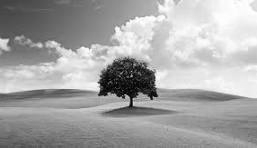

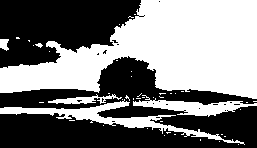

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)
# Calculate mean intensity
gray_image = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

threshold = np.mean(gray_image)
print("Threshold (mean intensity):", threshold)

# Apply threshold
_, binary_image = cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)

# Show images
cv2_imshow(gray_image)
cv2_imshow(binary_image)


Enter the threshold value(0-255): 125
Threshold (mean intensity): 125


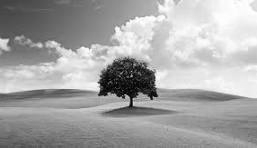

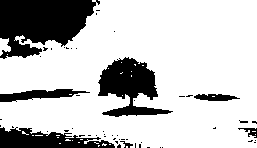

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)
# Calculate mean intensity
gray_image = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

threshold = int(input("Enter the threshold value(0-255): "))
print("Threshold (mean intensity):", threshold)

# Apply threshold
_, binary_image = cv2.threshold(gray_image, threshold, 255, cv2.THRESH_BINARY)

# Show images
cv2_imshow(gray_image)
cv2_imshow(binary_image)


# Question  2:-


| Case                | Formula Used                                 | Control                  |
| ------------------- | -------------------------------------------- | ------------------------ |
| **Case 1**          | Average: `(R + G + B)/3`                     | You fix the average rule |
| **Case 2**          | Custom weighted sum: `R*wR + G*wG + B*wB`    | User decides weights     |
| **OpenCV Built-in** | Fixed weights: `0.299 R + 0.587 G + 0.114 B` | No control (automatic)   |

These weighs may vary due to the human choice as its prefernce towards green,red and blue

Original image


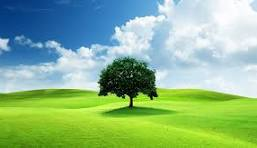





Gray_mean image


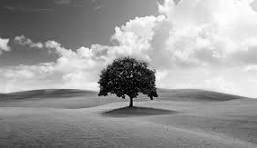





Enter the value for the R,G and B and make sure thier value should be between the 0 and 1 and also their sum should be 1
Enter the weightage of the R channel (Red): 0.3
Enter the weightage of the G channel (Green): 0.4
Enter the weightage of the B channel (Blue): 0.3
Gray_weighted image


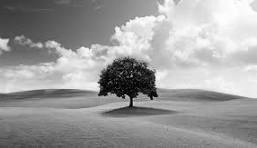

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)
print("Original image")
cv2_imshow(img)
B,G,R=cv2.split(img)
print("\n\n\n")

#Case 1 Mean_method
gray_mean=((R.astype(np.float32)+G.astype(np.float32)+B.astype(np.float32))/3).astype(np.uint8)
print("Gray_mean image")
cv2_imshow(gray_mean)
print("\n\n\n")
#Case 2 Weighted Average

print("Enter the value for the R,G and B and make sure thier value should be between the 0 and 1 and also their sum should be 1")

possible=False
while not possible:
  r = float(input("Enter the weightage of the R channel (Red): "))
  g = float(input("Enter the weightage of the G channel (Green): "))
  b = float(input("Enter the weightage of the B channel (Blue): "))

  is_sum_one = abs(r + g + b - 1.0) < 1e-9

        # Check if sum rules is met
  if is_sum_one:
      possible = True
      gray_weighted = ((R.astype(np.float32) * r) + (G.astype(np.float32) * g) + (B.astype(np.float32) * b)).astype(np.uint8)
      print("Gray_weighted image")
      cv2_imshow(gray_weighted)

  else:
    print("Enter the value again")







**🔹 R, G, B**
These are NumPy arrays representing the Red, Green, and Blue channels of the image. Each is a 2D array of pixel intensities from 0 to 255.

** .astype(np.float32)**

Each channel is converted from unsigned 8-bit integers (uint8) to 32-bit floating point numbers (float32).

**Why?**
To prevent overflow or rounding errors when doing arithmetic (like adding).
If you add three uint8 values and divide, it might wrap around if the sum exceeds 255.
Float allows for accurate division.

**.astype(np.uint8)**
The final averaged float result is converted back to uint8 (0 to 255) so it can be saved or displayed as a valid image.


**"Take the average of the R, G, B pixel values for each pixel, make sure the math is done using floats to avoid errors, then convert the result back to an image format (uint8)."**

#Question 3:-


Reads the image as grayscale.

Pixel values will range from 0 (black) to 255 (white).

Grayscale is used here to support both grayscale and binary images (binary images are just grayscale with only 0s and 255s).

Asks the user to enter the width (in pixels) of the border to add on all sides.

Example: if you enter 5, a 5-pixel border will be added on each side.

Asks the user for the color (intensity) of the border:

0 = black border

255 = white border

Any value in between is a shade of gray

Adds the actual padding (border) around the image.

top, bottom, left, right: how many pixels to add on each side.

cv2.BORDER_CONSTANT: means we're filling the added area with a constant value (not repeating edges or reflections).

value=border_color: the constant value used to fill the border area.

Saves the new image (with border) as a file named "padded_output.png".
Because **cmap only affects how the image is displayed** in matplotlib.pyplot.imshow()— it **does not modify the image data itself**. The saved image usingcv2.imwrite() is still grayscale because the actual image matrix (padded_img`) contains only intensity values (0–255), i.e., it's still a grayscale image in memory.

Enter border width (in pixels): 55
Enter border color (0-255): 150
The Original image


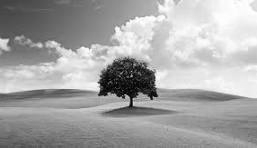

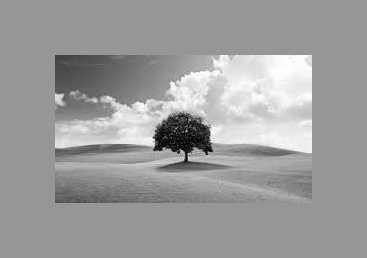

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)
gray_image = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


# User input
border_width = int(input("Enter border width (in pixels): "))
# user input
border_color = int(input("Enter border color (0-255): "))
# Add border (padding)
padded_img = cv2.copyMakeBorder(gray_image,
                                top=border_width,
                                bottom=border_width,
                                left=border_width,
                                right=border_width,
                                borderType=cv2.BORDER_CONSTANT,
                                value=border_color)

# Save result
print("The Original image")
cv2_imshow(gray_image)
cv2.imwrite("padded_output.png", padded_img)
cv2_imshow(padded_img)

#Question 4:-


###METHOD 1:-
cv2.bitwise_not(): This is the most straightforward OpenCV function for inversion. It performs a bitwise NOT operation on every element in the array, which for an 8-bit image is equivalent to 255−P.
###METHOD 2:-
NumPy Subtraction: The expression 255 - img is a fast and explicit way to calculate the negative using NumPy's array operations. Since img is a NumPy array, the subtraction is performed on every pixel simultaneously.

Example: A white pixel has a value of 255. The complement is 255−255=0 (black).

Example: A black pixel has a value of 0. The complement is 255−0=255 (white).

The Original image


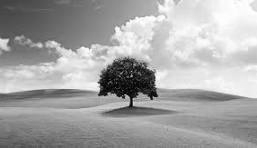

Image Complement (Negative)_1


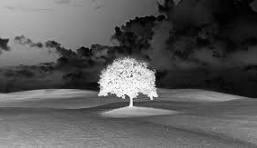

Image Complement (Negative)_2


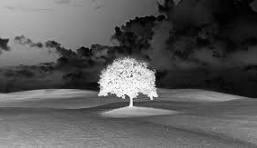

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)

gray_image = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print("The Original image")
cv2_imshow(gray_image)
#Method 1:-
complement_img_1 = cv2.bitwise_not(gray_image)
print("Image Complement (Negative)_1")
cv2_imshow(complement_img_1)
#Method 2:-
complement_img_2 = 255 - gray_image
print("Image Complement (Negative)_2")
cv2_imshow(complement_img_2)

#Question 5:-


| Transformation     | Formula                            | Effect                                       | Applications                  |
| ------------------ | ---------------------------------- | -------------------------------------------- | ----------------------------- |
| Log                | $s=c\log(1+r)$                     | Brighten dark, compress bright               | Satellite, medical images     |
| Inverse Log        | $s = \exp(r/c)-1$                  | Expand bright regions                        | Preprocessing bright images   |
| Gamma              | $s = c r^\gamma$                   | Brighten ($\gamma<1$) or darken ($\gamma>1$) | Correct displays, dark photos |
| Contrast Stretch   | $s=(r-r_\min)/(r_\max-r_\min)*255$ | Increase overall contrast                    | Low-contrast images           |
| Negative           | $s = L-1-r$                        | Invert image                                 | X-rays, negatives             |
| Gray-Level Slicing | Highlight certain intensities      | Emphasize features                           | Medical, satellite            |
| Bit-Plane Slicing  | Work with bits of pixel            | Extract features                             | Compression, analysis         |



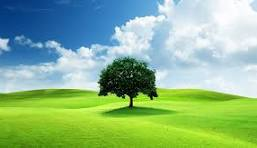

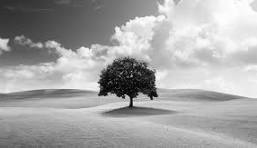

Left: Original | Right: Log Transformed


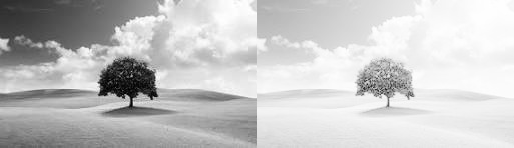

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)

cv2_imshow(img)

# Convert to grayscale
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2_imshow(img_gray)

# Log transformation
c = 1
log_transformed = c * np.log(1 + img_gray.astype(np.float32))
log_transformed = np.uint8(255 * log_transformed / np.max(log_transformed))

# Combine original and log-transformed images
combined = np.hstack((img_gray, log_transformed))
print("Left: Original | Right: Log Transformed")

cv2_imshow(combined)

| Technique        | Dark Pixels | Bright Pixels | Main Purpose              |
| ---------------- | ----------- | ------------- | ------------------------- |
| Log Transform    | Brighter    | Compressed    | Enhance dark details      |
| Contrast Stretch | Darker      | Brighter      | Increase overall contrast |


#Question 6:-

2
Left: Original | Right: Gamma Corrected


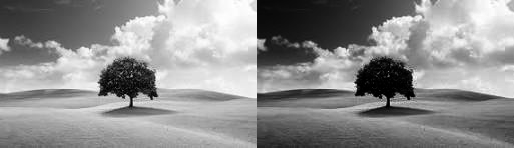

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)

# Convert to grayscale
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Gamma transformation
gamma = float(input()) # You can enter the value here
gamma_corrected = np.power(img_gray.astype(np.float32) / 255.0, gamma) * 255.0
gamma_corrected = np.uint8(gamma_corrected)

# Combine original and gamma-corrected images
combined_gamma = np.hstack((img_gray, gamma_corrected))
print("Left: Original | Right: Gamma Corrected")
cv2_imshow(combined_gamma)

IN Gamma it is majorly play around the dark pixels as when gamma < 1 it increase the dark pixels and less change in the bright pixels and whereas as when the gamma >1 it still change in the dark pixels making it smaller very slightly chaneg in the brght pixels

Used when:-
-when thier is the lightning issue


#QUESTION 7:-


In contrast stretching (also called intensity level stretching), we re-map the range of pixel intensities in the image so that they spread over a larger (or desired) range.

Why we do it
Some images have pixel intensities concentrated in a small range (e.g., 80–120).

This makes them look dull or low contrast.

By stretching that range to a wider one (e.g., 0–255), the image appears brighter and sharper.

The original image


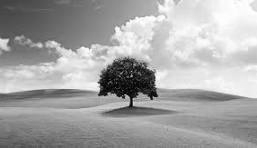

Detected r1 (min intensity) = 1
Detected r2 (max intensity) = 255
Streched Image


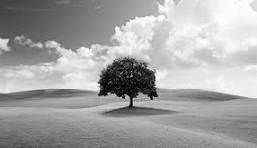

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)

gray_image = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print("The original image")
cv2_imshow(gray_image)
# Automatically get input intensity range from image
r1 = np.min(gray_image)
r2 = np.max(gray_image)
print(f"Detected r1 (min intensity) = {r1}")
print(f"Detected r2 (max intensity) = {r2}")

# Set output range (full contrast)
s1, s2 = 0, 255

# Contrast stretching formula
stretched = ((gray_image.astype(np.float32) - r1) / (r2 - r1)) * (s2 - s1) + s1
stretched = np.clip(stretched, 0, 255).astype(np.uint8)
print("Streched Image")
cv2_imshow(stretched)


Enter input range (r1 r2): 10 155
Enter output range (s1 s2): 45 68


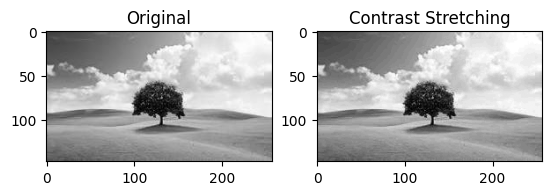

In [12]:
from google.colab import output
output.clear()
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)

gray_image = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


# Get input from user
r1, r2 = map(int, input("Enter input range (r1 r2): ").split()) #.split() is there because we want to give values for both r1 and r2 in a single input line.
s1, s2 = map(int, input("Enter output range (s1 s2): ").split())

# Contrast stretching
stretched = ((gray_image.astype(np.float32) - r1) / (r2 - r1)) * (s2 - s1) + s1
stretched = np.clip(stretched, 0, 255).astype(np.uint8)

# Show result
plt.subplot(1,2,1), plt.imshow(gray_image, cmap='gray'), plt.title('Original')
plt.subplot(1,2,2), plt.imshow(stretched, cmap='gray'), plt.title('Contrast Stretching')
plt.show()


# QUESTION 8:-


## HISTOGRAMIC EQUALIZATION
Histogram equalization is an image processing technique used to adjust the contrast of an image by modifying its pixel intensity distribution (its histogram). The goal is to make the intensities more evenly distributed across the full dynamic range (e.g., 0 to 255 for an 8-bit image).
####FORMULA USED
New_Value=⌊(CDF(P)−CDF
min
​
 )/(1−CDF
min
​
 )×(L−1)⌋

-Used to improve the contrast of the image by redistributing the pixel values in the histogram

The Original image


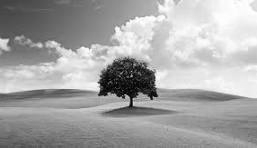

Equalized image


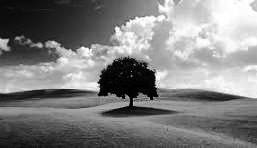

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)

gray_image = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
print("The Original image")
cv2_imshow(gray_image)

equalized = cv2.equalizeHist(gray_image)
print("Equalized image")
cv2_imshow(equalized)

#QUESTION 9:-

##HISTOGRAM MATCHING
Histogram matching, also known as histogram specification, is an image processing technique used to transform the pixel intensity distribution of one image (the input image) so that its histogram matches the shape of a specified, desired histogram (the reference histogram).

* Equalize the Input Image: Calculate the CDF of the input image and use it to transform the image's intensities to achieve a (hypothetically) uniform histogram. This intermediate step is called equalization.


* Target CDF
1
​
 =CDF
Input
​
 (Input_Intensity)
Equalize the Reference Histogram: Calculate the CDF of the desired reference histogram (or the reference image) to achieve its own (hypothetically) uniform distribution.

* Target CDF
2
​
 =CDF
Reference
​
 (Reference_Intensity)
Inverse Mapping: Find the mapping that translates the uniformly distributed intensities from Step 1 back to the distribution defined by the reference histogram's CDF (Step 2). This involves finding the inverse mapping from Target CDF
2
​
  to the Reference_Intensity values.


Input Image (Source)


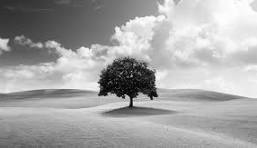


Reference Image


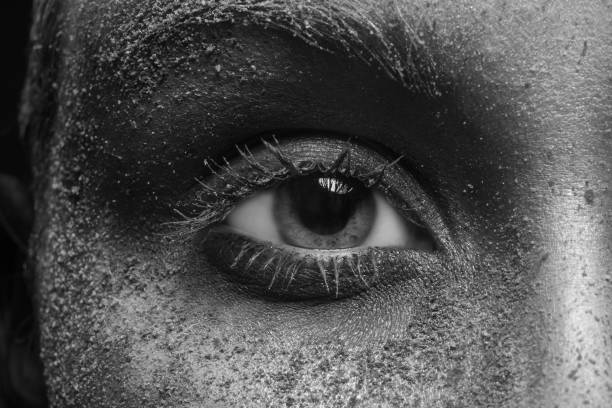


Matched Image (Output)


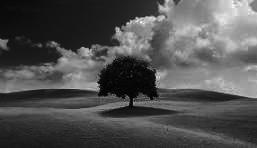


Saved matched image as: histogram_matched_output.png


In [17]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

# --- 1. Define Image Paths ---
# Use the paths defined by the user
img_path_source = '/content/drive/MyDrive/download.jpeg'
img_path_ref = '/content/drive/MyDrive/download2.jpg'
img_source = cv2.imread(img_path_source)
img_ref = cv2.imread(img_path_ref)
img_source_2 = cv2.cvtColor(img_source, cv2.COLOR_BGR2GRAY)
img_ref_2 = cv2.cvtColor(img_ref, cv2.COLOR_BGR2GRAY)



# --- 3. Histogram Matching Function ---
def hist_match(source, template):
    oldshape = source.shape
    source = source.ravel()
    template = template.ravel()

    s_values, bin_idx, s_counts = np.unique(source, return_inverse=True, return_counts=True)
    t_values, t_counts = np.unique(template, return_counts=True)

    # Calculate Source CDF
    s_quantiles = np.cumsum(s_counts).astype(np.float64)
    s_quantiles /= s_quantiles[-1]

    # Calculate Template CDF
    t_quantiles = np.cumsum(t_counts).astype(np.float64)
    t_quantiles /= t_quantiles[-1]

    # Interpolation: Map source CDF values to template intensity values
    interp_t_values = np.interp(s_quantiles, t_quantiles, t_values)

    # Apply the mapping
    matched = interp_t_values[bin_idx].reshape(oldshape)

    return matched.astype(np.uint8)


# --- 4. Perform Matching and Display (Remaining Block) ---
# Note: The conflicting image loading block has been removed.
img_matched = hist_match(img_source_2, img_ref_2)

images = [img_source_2, img_ref_2, img_matched]
titles = ['Input Image (Source)', 'Reference Image', 'Matched Image (Output)']

for i, title in enumerate(titles):
    print(f"\n{title}")
    cv2_imshow(images[i])

cv2.imwrite("histogram_matched_output.png", img_matched)
print("\nSaved matched image as: histogram_matched_output.png")

#QUESTION 10:-

1. Averaging Filter (cv2.blur)
Kernel: All elements are the same (e.g., 1/25 for a 5×5 kernel).

* Effect: Calculates the simple arithmetic mean of the pixel values under the kernel. This is a basic form of low-pass filtering, effective at reducing noise but tends to cause blurring of edges.

2. Custom Weighted Filter (h(x,y)=max(∣x∣,∣y∣))
Concept: This is a custom low-pass filter where the weights are determined by the specified function relative to the kernel's center (0,0).

* The function h(x,y)=max(∣x∣,∣y∣) produces a 'diamond' shape when mapped. The central pixel (where ∣x∣=∣y∣=0) gives a value of 0, and the corners give the maximum value.

  Implementation: For smoothing, pixels closer to the center must have a higher weight. The code inverts the weight map (e.g., W=max
val
​
 −h(x,y)) so the center gets the highest weight before normalization.

  Function: cv2.filter2D is the standard OpenCV function used to apply any arbitrary kernel (like the custom one we created) to an image.

3. Gaussian Filter (cv2.GaussianBlur)
Kernel: The weights are determined by a Gaussian (bell-shaped) function. Weights are highest at the center and drop off smoothly towards the edges.

* Effect: This filter is superior to the simple averaging filter because it assigns more importance to the pixels closest to the center. It smooths noise effectively while preserving edges better than the simple average, making it ideal for many image processing tasks.

  σ (Sigma): The sigmaX=0 parameter controls the degree of smoothing. A larger σ means a wider bell curve and greater blurring. Setting it to 0 tells OpenCV to calculate a suitable σ based on the kernel size.

--- Original Image (Grayscale with Noise) ---


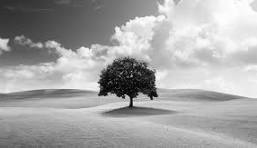


--- 1. Averaging Filter ---


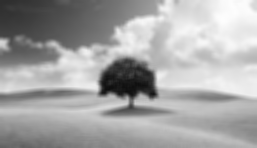


--- 2. Custom Weighted Filter: h(x,y) = max(|x|,|y|) ---


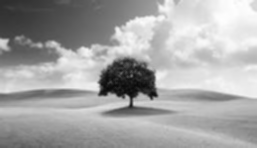


--- 3. Gaussian Filter ---


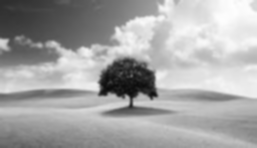


Results saved.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img_color = cv2.imread(img_path)
# Convert to grayscale for consistent filtering and easier visualization
original_img = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
original_img_copy = original_img.copy()

print("--- Original Image (Grayscale with Noise) ---")
cv2_imshow(original_img)

# Define filter size (kernel size)
ksize = 5 # Use a 5x5 kernel for noticeable smoothing

# --- 2. Averaging Filter (Un-weighted) ---
# A simple box filter where all kernel elements are equal (1/ksize^2).
# This is a standard low-pass filter.
print("\n--- 1. Averaging Filter ---")
# cv2.blur() is the standard function for an un-weighted averaging filter
smoothed_avg = cv2.blur(original_img_copy, (ksize, ksize))
cv2_imshow(smoothed_avg)


# --- 3. Weighted Filter given by h(x,y) = max(|x|,|y|) ---
# This is a custom filter, so we must manually construct the kernel and use cv2.filter2D.
print("\n--- 2. Custom Weighted Filter: h(x,y) = max(|x|,|y|) ---")

# Create the custom kernel
center = ksize // 2
kernel_custom = np.zeros((ksize, ksize), dtype=np.float32)

for i in range(ksize):
    for j in range(ksize):
        # Coordinates relative to the center (0, 0)
        x = i - center
        y = j - center
        # Calculate the weight h(x,y) = max(|x|,|y|)
        kernel_custom[i, j] = max(abs(x), abs(y))

# To make it a smoothing kernel, the sum must equal 1.
# We reverse the weights so that the center has the highest value (1.0) and edges have the lowest (0.0).
# Then normalize it so the sum is 1.

# Find max weight to normalize
max_val = np.max(kernel_custom)

# Invert the weights: higher weights mean more smoothing. Let's invert the relationship
# so the center (where max(|x|,|y|)=0) gets the highest weight, and corners get the lowest.
# A simple inverse map: Max_val - current_val
inverted_weights = max_val - kernel_custom
# Normalize the kernel by dividing by the sum of its elements
kernel_normalized = inverted_weights / np.sum(inverted_weights)

# Apply the custom kernel
smoothed_custom = cv2.filter2D(original_img_copy, -1, kernel_normalized)
cv2_imshow(smoothed_custom)


# --- 4. Gaussian Filter ---
# A very common and effective smoothing filter. Weights pixels based on a Gaussian (bell-shaped) curve.
print("\n--- 3. Gaussian Filter ---")
# sigmaX is the Gaussian standard deviation in the X direction. Set to 0 to be calculated automatically.
smoothed_gaussian = cv2.GaussianBlur(original_img_copy, (ksize, ksize), sigmaX=0)
cv2_imshow(smoothed_gaussian)

# Optional: Save results
cv2.imwrite("smoothed_avg.png", smoothed_avg)
cv2.imwrite("smoothed_custom.png", smoothed_custom)
cv2.imwrite("smoothed_gaussian.png", smoothed_gaussian)
print("\nResults saved.")

#QUESTION 11:-

* Laplacian Filter (Second Derivative)
Concept: The Laplacian filter calculates the second-order derivative of the image intensity. It detects pixels where the intensity changes rapidly in two orthogonal directions.

  Effect: It is an isotropic filter, meaning it detects edges regardless of their orientation, but it is sensitive to noise. In your code, the Laplacian output is added back to the original image to sharpen it, as the edges (high-frequency details) are emphasized.

* B. Sobel Operator (First Derivative)
Concept: The Sobel operator calculates the first-order gradient (derivative) of the image intensity. It uses two kernels (one for the X direction, one for the Y direction) to measure the change in intensity.

  Effect: The output provides the magnitude and direction of the edge. The magnitude (calculated using cv2.magnitude) shows the strength of the edge.

* C. Canny Edge Detector (Advanced Edge Detection)
Concept: Canny is not just a simple filter; it's a multi-stage algorithm considered optimal for edge detection.

Steps: It involves Gaussian smoothing (noise reduction), finding gradients (like Sobel), applying Non-Maximum Suppression (thinning the edges), and using hysteresis thresholding (connecting weak edges only if they are near strong edges) for robust and clean output.

* Unsharp Masking
This is a widely used and effective technique for practical sharpening, based on the principle of emphasizing high-frequency content.

  Concept: Sharpening is achieved by boosting the high-frequency components (details/edges) that are naturally suppressed by blurring.

  * Steps in the Code:

    * Blurring: A Gaussian filter (low-pass) is applied to the original image to create a smooth, blurred image.

    * Mask Creation: The blurred image is subtracted from the original image to obtain the unsharp mask (unsharp_mask). This mask contains only the high-frequency details (edges).

    * Sharpening: The mask is multiplied by an amplification factor (k=1.5) and then added back to the original image. This reintroduces and enhances the details, making the overall image look sharper.

Original Image


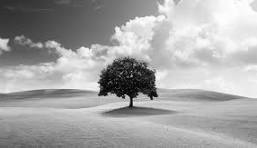


Laplacian Edges


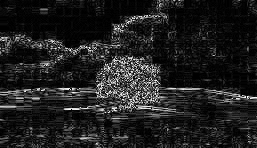


Laplacian Sharpened Image


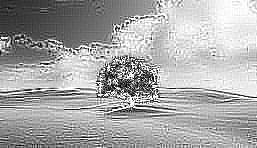


Sobel Edges (Magnitude)


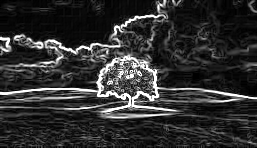


Canny Edges


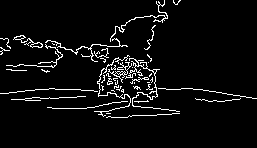


Unsharp Masking Sharpened Image


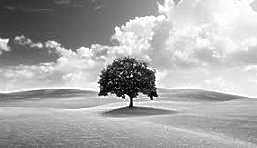

True

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img_color = cv2.imread(img_path)


img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
original_img = img_gray.copy()

print("Original Image")
cv2_imshow(original_img)

# 1. Laplacian Sharpening
laplacian = cv2.Laplacian(original_img, ddepth=cv2.CV_64F, ksize=3)
laplacian_abs = np.uint8(np.absolute(laplacian))
sharpened_laplacian = cv2.convertScaleAbs(original_img + laplacian)

print("\nLaplacian Edges")
cv2_imshow(laplacian_abs)
print("\nLaplacian Sharpened Image")
cv2_imshow(sharpened_laplacian)

# 2. Gradient Operators (Sobel and Canny edge detector)
sobelx = cv2.Sobel(original_img, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(original_img, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobelx, sobely)
sobel_edges = cv2.convertScaleAbs(sobel_magnitude)
canny_edges = cv2.Canny(original_img, threshold1=100, threshold2=200)

print("\nSobel Edges (Magnitude)")
cv2_imshow(sobel_edges)
print("\nCanny Edges")
cv2_imshow(canny_edges)

# 3. Unsharp Masking (Gaussian filter 5x5 and sigma=3)
blurred_img = cv2.GaussianBlur(original_img, (5, 5), sigmaX=3)
unsharp_mask = cv2.subtract(original_img, blurred_img)
k = 1.5
sharpened_unsharp = cv2.addWeighted(original_img, 1.0, unsharp_mask, k, 0)
sharpened_unsharp = np.clip(sharpened_unsharp, 0, 255).astype(np.uint8)

print("\nUnsharp Masking Sharpened Image")
cv2_imshow(sharpened_unsharp)

cv2.imwrite("sharpened_laplacian.png", sharpened_laplacian)
cv2.imwrite("sharpened_unsharp_masking.png", sharpened_unsharp)

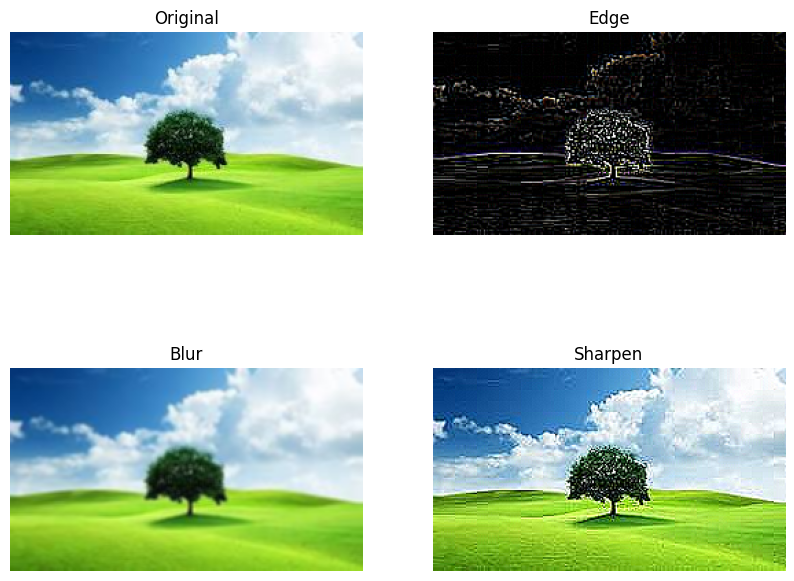

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

img_path = '/content/drive/MyDrive/download.jpeg'
img = cv2.imread(img_path)


# Check if the image was loaded successfully
if img is None:
    print("Error: Could not load image.")
else:
    # Convert BGR -> RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Kernels
    edge_kernel = np.array([[-1, -1, -1],
                            [-1,  8, -1],
                            [-1, -1, -1]])
    blur_kernel = np.ones((3,3), np.float32) / 9
    sharpen_kernel = np.array([[0, -1, 0],
                               [-1, 5, -1],
                               [0, -1, 0]])

    # Apply filters
    edge_img = cv2.filter2D(img, -1, edge_kernel)
    blur_img = cv2.filter2D(img, -1, blur_kernel)
    sharpen_img = cv2.filter2D(img, -1, sharpen_kernel)

    # Display results with matplotlib
    titles = ["Original", "Edge", "Blur", "Sharpen"]
    images = [img, edge_img, blur_img, sharpen_img]

    plt.figure(figsize=(10,8))
    for i in range(4):
        plt.subplot(2,2,i+1)
        plt.imshow(images[i])
        plt.title(titles[i])
        plt.axis("off")
    plt.show()
